# Activation histograms of randomly chosen units

For each condition, draws a few random units and plots the distribution of their activation over the cached uniform
sample of training tokens (`cache/train/L*/uniform.npz`).

Values are shown the way the explainer sees them: oriented to the unit's primary pole and divided by its corpus
maximum, **s·z / ref** (see `export.py`). The dashed line is the `corpus_frac` "fires strongly" threshold
(`scoring.strong_frac`, 0.3). The y-axis is log-scale, so heavy tails are visible.

Set `RUN` to the run directory. Change `SEED` to draw different units.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import kurtosis

RUN = Path.home() / "combo_runs" / "qwen3_0.6b_small_v2"
LAYERS = [7, 14, 21]
UNITS_PER_COND = 4
SEED = 0
STRONG_FRAC = 0.3
BINS = 120
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 8, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
def load_layer(L):
    """Unit metadata, uniform-sample activations, and the pole / reference value of every unit at layer L."""
    D = RUN / "data"
    meta = [json.loads(l) for l in open(D / f"units/L{L}/meta.jsonl")]
    us, big = np.load(D / f"units/L{L}/units.npz"), np.load(D / f"cache/train/L{L}/topk_big.npz")
    acts = np.load(D / f"cache/train/L{L}/uniform.npz")["acts"]
    mu, sd = us["mean_u"], np.maximum(us["std_u"], 1e-12)
    pv, nv = big["pos_vals"][:, 0], big["neg_vals"][:, 0]
    s = np.where((pv - mu) / sd >= (mu - nv) / sd, 1, -1)       # primary pole, as in export.py
    ref = np.where(s > 0, pv, -nv)
    return meta, acts, s, ref

layers = {L: load_layer(L) for L in LAYERS}
conds = list(dict.fromkeys(m["cond"] for m in layers[LAYERS[0]][0]))
print("conditions:", conds)

conditions: ['neuron', 'dense_raw', 'dense_white', 'ksparse_2', 'ksparse_5', 'ksparse_20', 'ksparse_100', 'related_5', 'related_20']


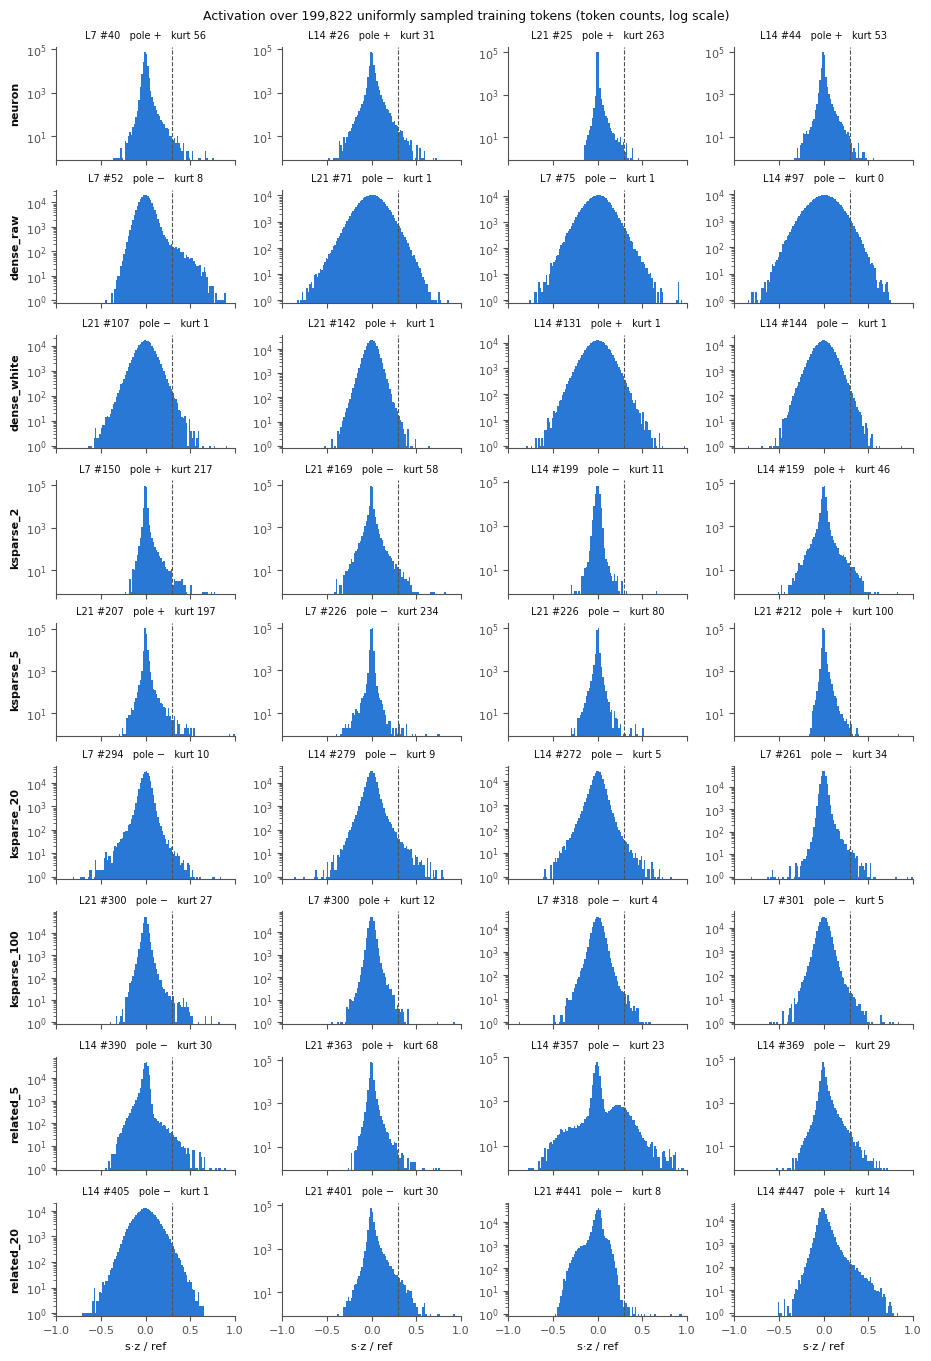

In [3]:
rng = np.random.default_rng(SEED)
picks = {}                                          # cond -> list of (layer, col)
for c in conds:
    pool = [(L, m["col"]) for L in LAYERS for m in layers[L][0] if m["cond"] == c and layers[L][3][m["col"]] > 0]
    picks[c] = [pool[i] for i in rng.choice(len(pool), UNITS_PER_COND, replace=False)]

fig, axes = plt.subplots(len(conds), UNITS_PER_COND, figsize=(2.3 * UNITS_PER_COND, 1.5 * len(conds)),
                         sharex=True, constrained_layout=True)
for r, c in enumerate(conds):
    for k, (L, col) in enumerate(picks[c]):
        meta, acts, s, ref = layers[L]
        v = s[col] * acts[:, col].astype(np.float64) / ref[col]
        ax = axes[r, k]
        ax.hist(v, bins=np.linspace(-1, 1, BINS + 1), color=BLUE, log=True)
        ax.axvline(STRONG_FRAC, color=MUTED, lw=0.8, ls="--")
        ax.set_xlim(-1, 1)
        ax.set_ylim(0.8, None)
        ax.set_title(f"L{L} #{col}   pole {'+' if s[col] > 0 else '−'}   kurt {kurtosis(v):.0f}", color=INK, fontsize=7)
        if k == 0:
            ax.set_ylabel(c, color=INK, fontsize=8, fontweight="bold")
for ax in axes[-1]:
    ax.set_xlabel("s·z / ref")
fig.suptitle(f"Activation over {len(acts):,} uniformly sampled training tokens (token counts, log scale)",
             color=INK, fontsize=9)
fig.savefig(RUN.parent / "unit_histograms.png", dpi=150)
plt.show()

## Pooled shape by condition

Every unit's activation z-scored, s·(z − μ)/σ, pooled over all units of a condition. This compares the shape of the
distributions without the max normalization. The x-range is clipped to [−10, 40]; the neuron and sparse tails continue beyond it. Kurtosis is the median over the condition's units.

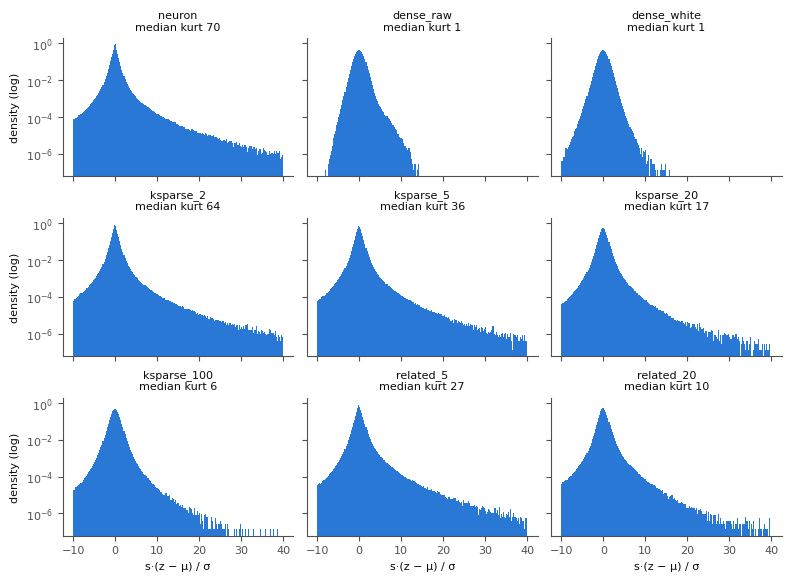

In [4]:
ncol = 3
nrow = -(-len(conds) // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 1.9 * nrow), sharex=True, sharey=True, constrained_layout=True)
edges = np.linspace(-10, 40, 201)
for ax in axes.flat[len(conds):]:
    ax.set_visible(False)
for ax, c in zip(axes.flat, conds):
    zs, ks = [], []
    for L in LAYERS:
        meta, acts, s, ref = layers[L]
        cols = [m["col"] for m in meta if m["cond"] == c and ref[m["col"]] > 0]
        a = acts[:, cols].astype(np.float64) * s[cols]
        z = (a - a.mean(0)) / np.maximum(a.std(0), 1e-12)
        zs.append(z.ravel()); ks += list(kurtosis(z, axis=0))
    ax.hist(np.concatenate(zs), bins=edges, color=BLUE, density=True, log=True)
    ax.set_title(f"{c}\nmedian kurt {np.median(ks):.0f}", color=INK, fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("s·(z − μ) / σ")
for ax in axes[:, 0]:
    ax.set_ylabel("density (log)")
fig.savefig(RUN.parent / "unit_histograms_pooled.png", dpi=150)
plt.show()